<a href="https://colab.research.google.com/github/Tanvibhosale-04/brain-tumor-classification/blob/main/Brain_Tumor_Model_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'Aadhar', 'Classroom', 'SEM 7 Result .pdf', 'Modified MIS_REV_01.SLDDRW', 'Lighter than Air Systems certificate.pdf', 'NPTEL RECEIPT & RESULT.pdf', 'passbook pdf.pdf', 'Google AI Studio', 'Sarjerao patil (9890645256)\n26-5-2025\nVehicle No-....gsheet', 'Prototyping presentation.gslides', 'Minutes of Meetings Preparation.gvid', 'Advanced MoM Documentation & Governance.gslides', 'Practical Example of MOM Preparation.gslides', 'Minutes of Meetings Preparation.gslides', 'Brain_Tumor_Dataset', 'custom_cnn.keras', 'cnn_results.txt', 'cnn_accuracy.png', 'cnn_loss.png', 'cnn_confusion_matrix.png']


In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"tanvirameshbhosale04","key":"7a5ef8da128592b23039de1cdc3d142b"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset

Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:04<00:00, 37.2MB/s]



In [ ]:
!unzip -q brain-tumor-mri-dataset.zip

In [ ]:
!ls

brain-tumor-mri-dataset.zip  kaggle.json  sample_data  Testing	Training


In [ ]:
import os

train_path = "/content/Training"
test_path = "/content/Testing"

for folder in os.listdir(train_path):
    print(folder, ":", len(os.listdir(os.path.join(train_path, folder))))

glioma : 1400
notumor : 1400
pituitary : 1400
meningioma : 1400


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224,224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    "/content/Training",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

val_generator = train_datagen.flow_from_directory(
    "/content/Training",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    "/content/Testing",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 4480 images belonging to 4 classes.
Found 1120 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

cnn_model = Sequential([

    Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),

    Dense(256, activation='relu'),
    Dropout(0.5),

    Dense(4, activation='softmax')
])

cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    22,151,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,245,700 (84.86 MB)

 Trainable params: 22,245,700 (84.86 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_cnn = cnn_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 24s 113ms/step - accuracy: 0.7018 - loss: 0.7991 - val_accuracy: 0.8009 - val_loss: 0.5126
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 95ms/step - accuracy: 0.8583 - loss: 0.4049 - val_accuracy: 0.8696 - val_loss: 0.3649
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 98ms/step - accuracy: 0.8993 - loss: 0.2845 - val_accuracy: 0.8679 - val_loss: 0.3225
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.9295 - loss: 0.2096 - val_accuracy: 0.9018 - val_loss: 0.2687
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.9502 - loss: 0.1493 - val_accuracy: 0.9205 - val_loss: 0.2383
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 94ms/step - accuracy: 0.9612 - loss: 0.1042 - val_accuracy: 0.9161 - val_loss: 0.2645
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 95ms/step - accuracy: 0.9717 - loss: 0.0817 - val_accuracy: 0.9232 - val_loss: 0.2804
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 95ms/step - accuracy: 0.9661 - loss: 0.1004 -

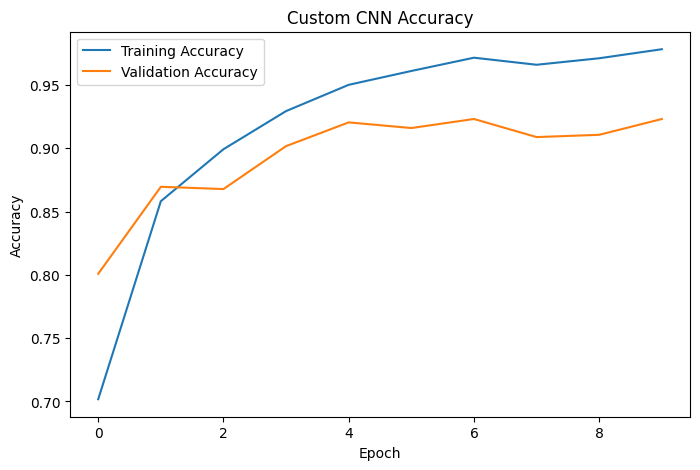

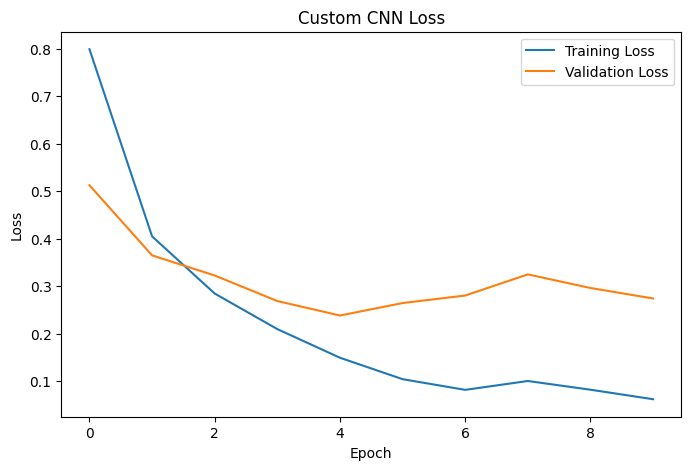

In [ ]:
import matplotlib.pyplot as plt

# Accuracy
plt.figure(figsize=(8,5))
plt.plot(history_cnn.history['accuracy'], label='Training Accuracy')
plt.plot(history_cnn.history['val_accuracy'], label='Validation Accuracy')
plt.title('Custom CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Loss
plt.figure(figsize=(8,5))
plt.plot(history_cnn.history['loss'], label='Training Loss')
plt.plot(history_cnn.history['val_loss'], label='Validation Loss')
plt.title('Custom CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
loss, accuracy = cnn_model.evaluate(test_generator)

print("Test Accuracy:", accuracy)
print("Test Loss:", loss)

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 78ms/step - accuracy: 0.8519 - loss: 1.4369
Test Accuracy: 0.8518750071525574
Test Loss: 1.4368600845336914


In [ ]:
import numpy as np
from sklearn.metrics import classification_report

predictions = cnn_model.predict(test_generator)

y_pred = np.argmax(predictions, axis=1)

print(
    classification_report(
        test_generator.classes,
        y_pred,
        target_names=list(test_generator.class_indices.keys())
    )
)

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step
              precision    recall  f1-score   support

      glioma       0.92      0.70      0.80       400
  meningioma       0.77      0.81      0.79       400
     notumor       0.78      1.00      0.88       400
   pituitary       0.98      0.90      0.94       400

    accuracy                           0.85      1600
   macro avg       0.87      0.85      0.85      1600
weighted avg       0.87      0.85      0.85      1600



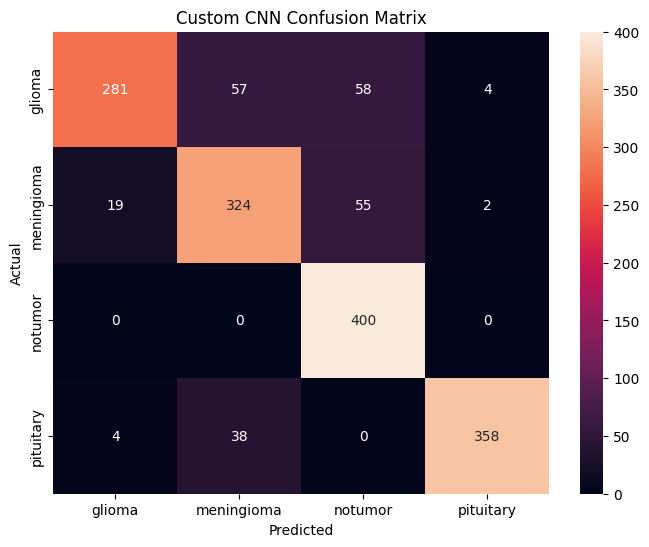

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(
    test_generator.classes,
    y_pred
)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=list(test_generator.class_indices.keys()),
            yticklabels=list(test_generator.class_indices.keys()))

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Custom CNN Confusion Matrix")
plt.show()

In [ ]:
import os

glioma_folder = "/content/Testing/glioma"

print(os.listdir(glioma_folder)[:5])

['Te-gl_62.jpg', 'Te-gl_356.jpg', 'Te-gl_190.jpg', 'Te-gl_45.jpg', 'Te-gl_219.jpg']


Selected Image: Te-gl_90.jpg


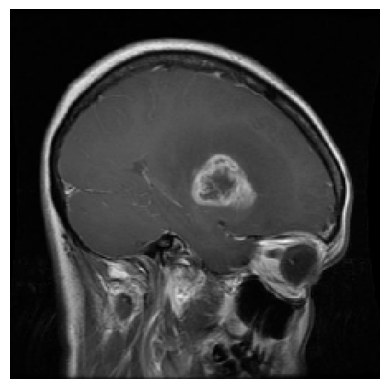

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 857ms/step
Actual Class: glioma
Predicted Class: glioma
Confidence: 99.82%


In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing import image

# Pick a random image from the glioma folder
glioma_folder = "/content/Testing/glioma"

random_image = random.choice(os.listdir(glioma_folder))
img_path = os.path.join(glioma_folder, random_image)

print("Selected Image:", random_image)

# Load and display image
img = image.load_img(img_path, target_size=(224,224))

plt.imshow(img)
plt.axis('off')
plt.show()

# Prepare image for prediction
img_array = image.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = cnn_model.predict(img_array)

classes = ['glioma','meningioma','notumor','pituitary']

predicted_class = classes[np.argmax(prediction)]
confidence = np.max(prediction) * 100

print("Actual Class: glioma")
print("Predicted Class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

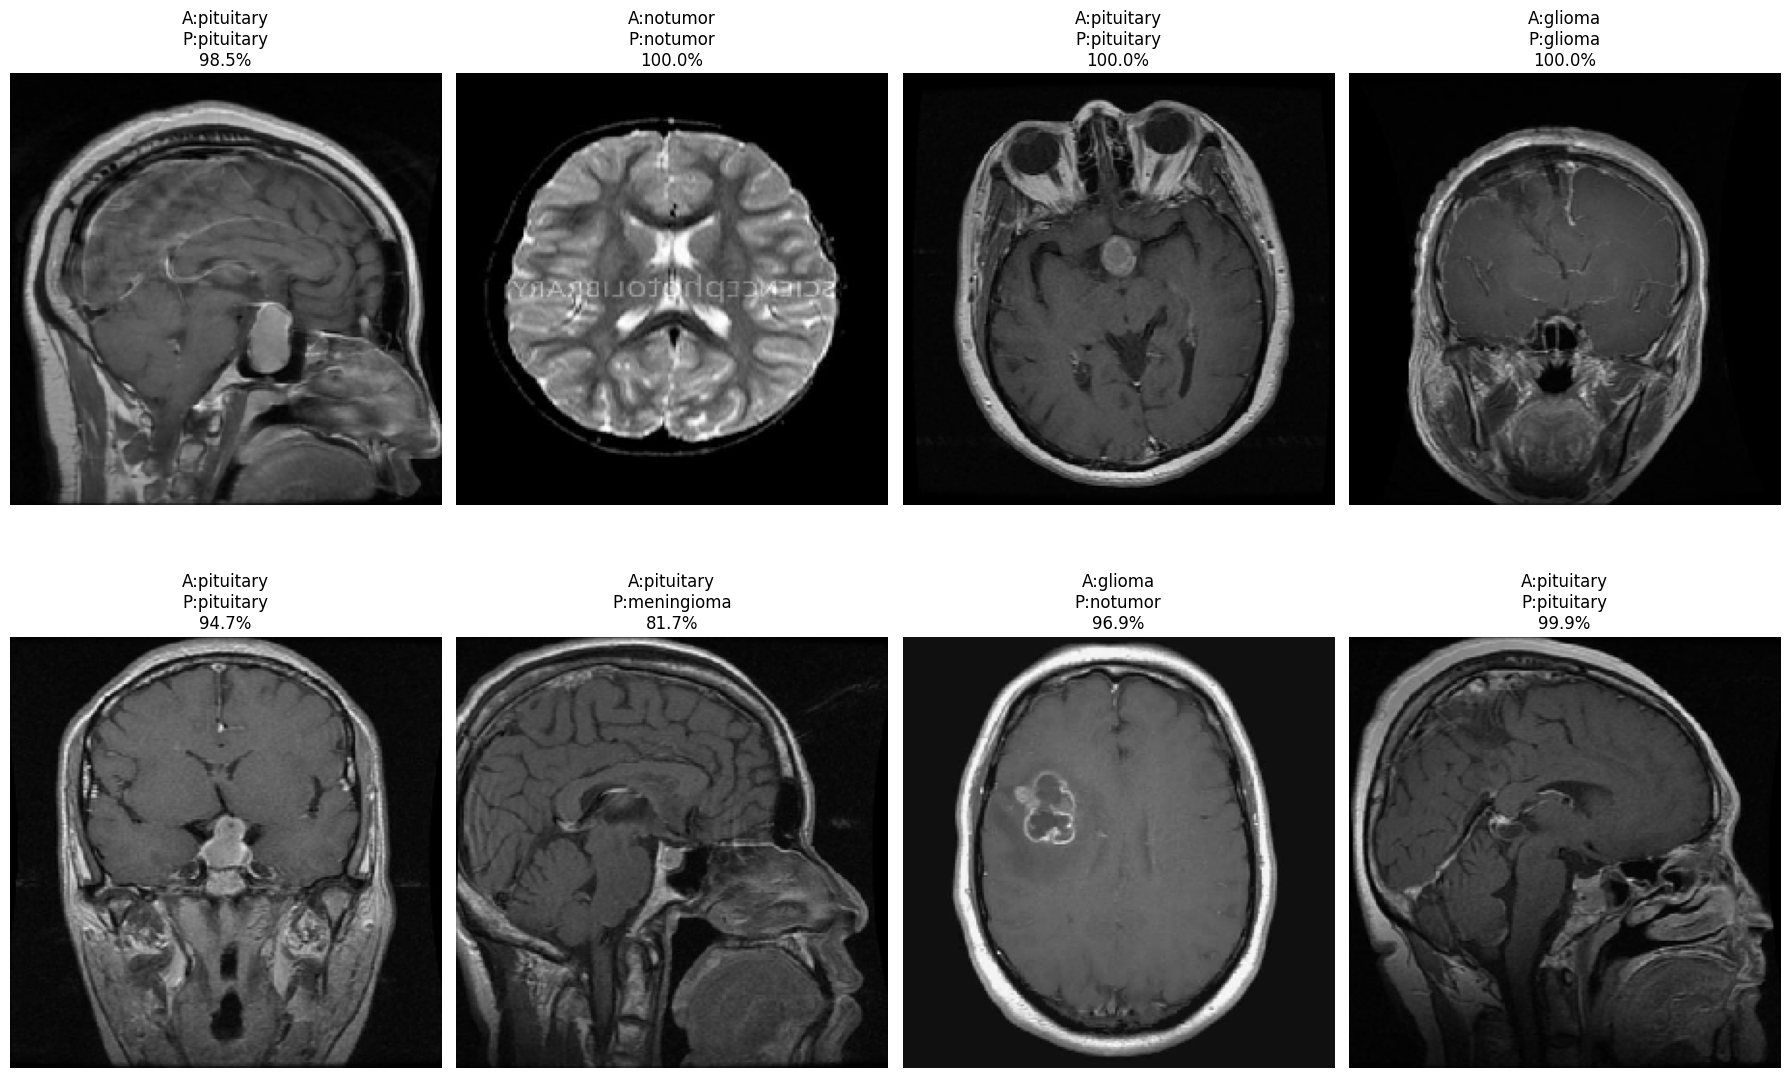

In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

classes = ['glioma', 'meningioma', 'notumor', 'pituitary']

plt.figure(figsize=(18,12))

for i in range(8):

    actual_class = random.choice(classes)

    folder = f"/content/Testing/{actual_class}"

    img_name = random.choice(os.listdir(folder))
    img_path = os.path.join(folder, img_name)

    img = image.load_img(img_path, target_size=(224,224))

    img_array = image.img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    prediction = cnn_model.predict(img_array, verbose=0)

    predicted_class = classes[np.argmax(prediction)]
    confidence = np.max(prediction) * 100

    plt.subplot(2,4,i+1)
    plt.imshow(img)
    plt.axis('off')

    plt.title(
        f"A:{actual_class}\nP:{predicted_class}\n{confidence:.1f}%"
    )

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image

# Use the same image path you tested before
img_path = "/content/Testing/glioma/Te-gl_173.jpg"

img = image.load_img(img_path, target_size=(224,224))
img_array = image.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = cnn_model.predict(img_array, verbose=0)

classes = ['glioma', 'meningioma', 'notumor', 'pituitary']

for cls, prob in zip(classes, prediction[0]):
    print(f"{cls}: {prob*100:.2f}%")

glioma: 90.14%
meningioma: 9.66%
notumor: 0.00%
pituitary: 0.20%


In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image

# Use the same image path you tested before
img_path = "/content/Testing/glioma/Te-gl_157.jpg"

img = image.load_img(img_path, target_size=(224,224))
img_array = image.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = cnn_model.predict(img_array, verbose=0)

classes = ['glioma', 'meningioma', 'notumor', 'pituitary']

for cls, prob in zip(classes, prediction[0]):
    print(f"{cls}: {prob*100:.2f}%")

glioma: 47.62%
meningioma: 52.33%
notumor: 0.04%
pituitary: 0.00%


In [ ]:
cnn_model.save('/content/drive/MyDrive/custom_cnn.keras')

In [ ]:
import os
print('custom_cnn.keras' in os.listdir('/content/drive/MyDrive'))

True


In [ ]:
results = """
Custom CNN Results

Training Accuracy: 98.39%
Validation Accuracy: 93.30%
Test Accuracy: 87.56%
Training Time: ~3 minutes

Interesting Misclassification:
Actual Class: Glioma
Predicted Class: Meningioma
Confidence: 79%
"""

with open('/content/drive/MyDrive/cnn_results.txt', 'w') as f:
    f.write(results)

print("Results file saved successfully!")

Results file saved successfully!


In [ ]:
plt.savefig('/content/drive/MyDrive/cnn_accuracy.png')
plt.savefig('/content/drive/MyDrive/cnn_loss.png')
plt.savefig('/content/drive/MyDrive/cnn_confusion_matrix.png')

<Figure size 640x480 with 0 Axes>

In [ ]:
import tensorflow as tf
tf.keras.backend.clear_session()

In [ ]:
print(train_generator.samples)
print(val_generator.samples)

4480
1120


In [ ]:
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
IMG_SIZE = (224,224)
BATCH_SIZE = 32

resnet_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

train_generator_resnet = resnet_datagen.flow_from_directory(
    "/content/Training",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

val_generator_resnet = resnet_datagen.flow_from_directory(
    "/content/Training",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

test_datagen_resnet = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_generator_resnet = test_datagen_resnet.flow_from_directory(
    "/content/Testing",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 4480 images belonging to 4 classes.
Found 1120 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.


In [ ]:
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [ ]:
x = base_model.output
x = GlobalAveragePooling2D()(x)

x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)

predictions = Dense(4, activation='softmax')(x)

resnet_model = Model(
    inputs=base_model.input,
    outputs=predictions
)

In [ ]:
resnet_model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
resnet_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,113,284 (91.98 MB)

 Trainable params: 525,572 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
history_resnet = resnet_model.fit(
    train_generator_resnet,
    validation_data=val_generator_resnet,
    epochs=5
)

Epoch 1/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 129ms/step - accuracy: 0.6656 - loss: 1.5572 - val_accuracy: 0.8384 - val_loss: 0.4227
Epoch 2/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 138ms/step - accuracy: 0.8328 - loss: 0.4307 - val_accuracy: 0.8839 - val_loss: 0.3346
Epoch 3/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 133ms/step - accuracy: 0.8641 - loss: 0.3625 - val_accuracy: 0.8938 - val_loss: 0.2987
Epoch 4/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 131ms/step - accuracy: 0.8842 - loss: 0.3174 - val_accuracy: 0.8857 - val_loss: 0.3069
Epoch 5/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 135ms/step - accuracy: 0.8991 - loss: 0.2814 - val_accuracy: 0.9143 - val_loss: 0.2515


In [ ]:
test_loss_resnet, test_acc_resnet = resnet_model.evaluate(
    test_generator_resnet
)

print("ResNet50 Test Accuracy:", test_acc_resnet)
print("ResNet50 Test Loss:", test_loss_resnet)

50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - accuracy: 0.8531 - loss: 0.4609
ResNet50 Test Accuracy: 0.8531249761581421
ResNet50 Test Loss: 0.4608932137489319


In [ ]:
class_names = list(test_generator_resnet.class_indices.keys())

print(class_names)

['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
import numpy as np

y_pred_resnet = resnet_model.predict(test_generator_resnet)

y_pred_classes_resnet = np.argmax(y_pred_resnet, axis=1)

y_true_resnet = test_generator_resnet.classes

50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step


In [ ]:
from sklearn.metrics import confusion_matrix

cm_resnet = confusion_matrix(
    y_true_resnet,
    y_pred_classes_resnet
)

print(cm_resnet)

[[267  84  39  10]
 [ 12 320  37  31]
 [  0   3 397   0]
 [  1  18   0 381]]


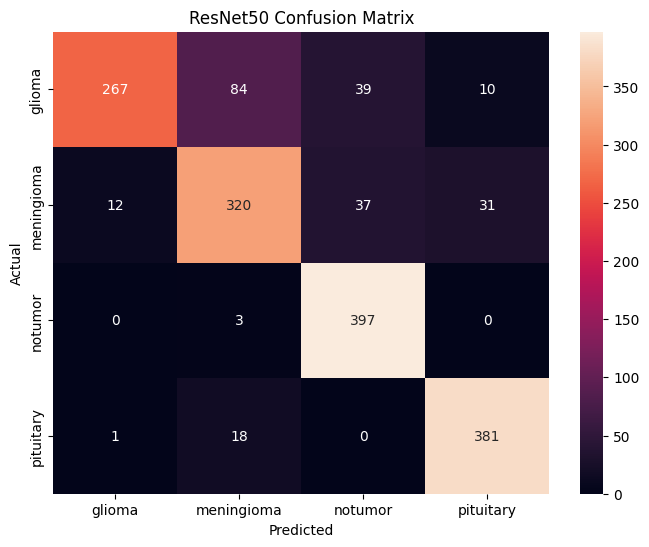

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))

sns.heatmap(
    cm_resnet,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ResNet50 Confusion Matrix")

plt.show()

In [ ]:
from sklearn.metrics import classification_report

class_names = list(test_generator_resnet.class_indices.keys())

print(
    classification_report(
        y_true_resnet,
        y_pred_classes_resnet,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

      glioma       0.95      0.67      0.79       400
  meningioma       0.75      0.80      0.78       400
     notumor       0.84      0.99      0.91       400
   pituitary       0.90      0.95      0.93       400

    accuracy                           0.85      1600
   macro avg       0.86      0.85      0.85      1600
weighted avg       0.86      0.85      0.85      1600



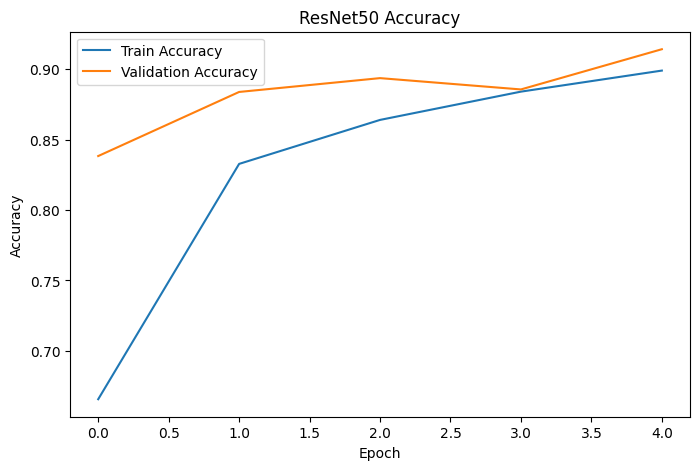

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history_resnet.history['accuracy'])
plt.plot(history_resnet.history['val_accuracy'])

plt.title('ResNet50 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend(['Train Accuracy','Validation Accuracy'])


plt.show()


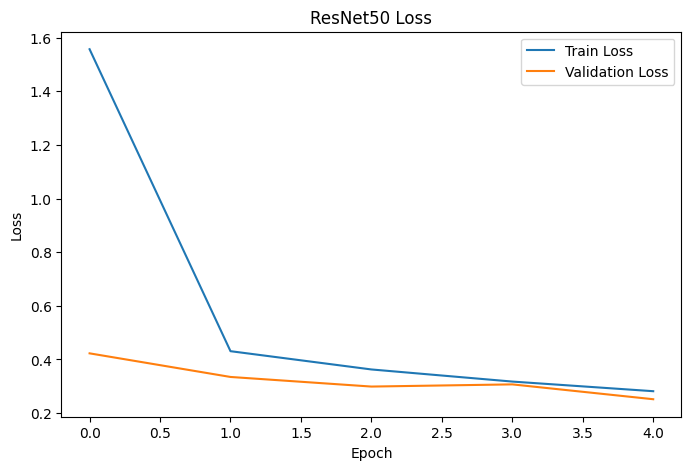

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history_resnet.history['loss'])
plt.plot(history_resnet.history['val_loss'])

plt.title('ResNet50 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend(['Train Loss','Validation Loss'])

plt.show()

In [ ]:
import os

base = "/content/drive/MyDrive/Brain_Tumor_Research"

folders = [
    "CNN",
    "ResNet50",
    "MobileNetV2",
    "GradCAM"
]

for folder in folders:
    os.makedirs(os.path.join(base, folder), exist_ok=True)

print("✅ Research folders created successfully!")

✅ Research folders created successfully!


In [ ]:
plt.savefig('/content/drive/MyDrive/Brain_Tumor_Research/ResNet50/ResNet50_Accuracy.png',
            dpi=300,
            bbox_inches='tight')
plt.savefig('/content/drive/MyDrive/Brain_Tumor_Research/ResNet50/ResNet50_Loss.png',
            dpi=300,
            bbox_inches='tight')
plt.savefig('/content/drive/MyDrive/Brain_Tumor_Research/ResNet50/ResNet50_ConfusionMatrix.png',
            dpi=300,
            bbox_inches='tight')
resnet_model.save(
    '/content/drive/MyDrive/Brain_Tumor_Research/ResNet50/resnet50_model.keras'
)

<Figure size 640x480 with 0 Axes>

In [ ]:
import tensorflow as tf
tf.keras.backend.clear_session()

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
IMG_SIZE = (224,224)
BATCH_SIZE = 32

mobilenet_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

train_generator_mobilenet = mobilenet_datagen.flow_from_directory(
    "/content/Training",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

val_generator_mobilenet = mobilenet_datagen.flow_from_directory(
    "/content/Training",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

test_datagen_mobilenet = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_generator_mobilenet = test_datagen_mobilenet.flow_from_directory(
    "/content/Testing",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 4480 images belonging to 4 classes.
Found 1120 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.


In [ ]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
x = base_model.output
x = GlobalAveragePooling2D()(x)

x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)

predictions = Dense(4, activation='softmax')(x)

mobilenet_model = Model(inputs=base_model.input, outputs=predictions)

In [ ]:
mobilenet_model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
mobilenet_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,586,948 (9.87 MB)

 Trainable params: 328,964 (1.25 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
history_mobilenet = mobilenet_model.fit(
    train_generator_mobilenet,
    validation_data=val_generator_mobilenet,
    epochs=5
)

Epoch 1/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 39s 136ms/step - accuracy: 0.6342 - loss: 0.9211 - val_accuracy: 0.8304 - val_loss: 0.4965
Epoch 2/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 97ms/step - accuracy: 0.8085 - loss: 0.5171 - val_accuracy: 0.8732 - val_loss: 0.3776
Epoch 3/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 100ms/step - accuracy: 0.8478 - loss: 0.4154 - val_accuracy: 0.8750 - val_loss: 0.3427
Epoch 4/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 102ms/step - accuracy: 0.8705 - loss: 0.3617 - val_accuracy: 0.8848 - val_loss: 0.3128
Epoch 5/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 101ms/step - accuracy: 0.8752 - loss: 0.3330 - val_accuracy: 0.8911 - val_loss: 0.2883


In [ ]:
print(history_mobilenet.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


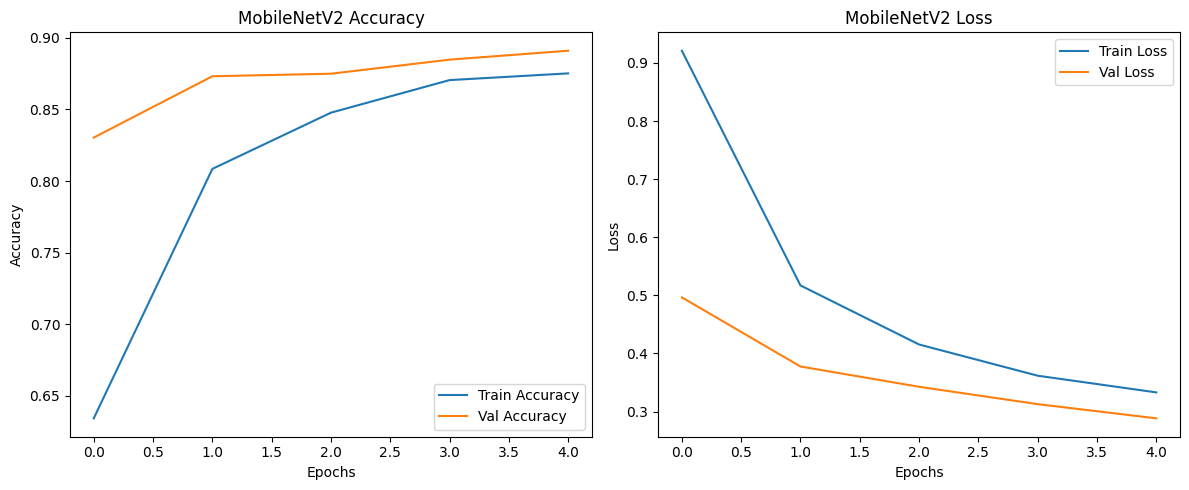

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history_mobilenet.history['accuracy'], label='Train Accuracy')
plt.plot(history_mobilenet.history['val_accuracy'], label='Val Accuracy')
plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history_mobilenet.history['loss'], label='Train Loss')
plt.plot(history_mobilenet.history['val_loss'], label='Val Loss')
plt.title("MobileNetV2 Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
plt.savefig("/content/drive/MyDrive/Brain_Tumor_Research/mobilenet_training_plot.png",
            dpi=300,
            bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image

# CHANGE THIS PATH to your test image
img_path = "/content/Testing/glioma/Te-gl_173.jpg"

# Load image
img = image.load_img(img_path, target_size=(224,224))

# Convert to array
img_array = image.img_to_array(img)

# Expand dimensions (model expects batch)
img_array = np.expand_dims(img_array, axis=0)

# IMPORTANT: use correct preprocessing for MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
img_array = preprocess_input(img_array)

# Predict
prediction = mobilenet_model.predict(img_array)

# Classes
classes = ['glioma', 'meningioma', 'notumor', 'pituitary']

# Output
pred_class = classes[np.argmax(prediction)]
confidence = np.max(prediction) * 100

print("Predicted Class:", pred_class)
print("Confidence:", confidence)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
Predicted Class: glioma
Confidence: 98.11297


In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image

# CHANGE THIS PATH to your test image
img_path = "/content/Testing/glioma/Te-gl_157.jpg"

# Load image
img = image.load_img(img_path, target_size=(224,224))

# Convert to array
img_array = image.img_to_array(img)

# Expand dimensions (model expects batch)
img_array = np.expand_dims(img_array, axis=0)

# IMPORTANT: use correct preprocessing for MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
img_array = preprocess_input(img_array)

# Predict
prediction = mobilenet_model.predict(img_array)

# Classes
classes = ['glioma', 'meningioma', 'notumor', 'pituitary']

# Output
pred_class = classes[np.argmax(prediction)]
confidence = np.max(prediction) * 100

print("Predicted Class:", pred_class)
print("Confidence:", confidence)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
Predicted Class: meningioma
Confidence: 64.945724


In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input

# CHANGE THIS PATH
img_path = "/content/Testing/glioma/Te-gl_175.jpg"

# Load image
img = image.load_img(img_path, target_size=(224,224))

# Convert to array
img_array = image.img_to_array(img)

# Expand dims (batch format)
img_array = np.expand_dims(img_array, axis=0)

# ResNet50 preprocessing (IMPORTANT)
img_array = preprocess_input(img_array)

# Predict
prediction = resnet_model.predict(img_array)

# Class labels (same order used in training)
classes = ['glioma', 'meningioma', 'notumor', 'pituitary']

# Output
pred_class = classes[np.argmax(prediction)]
confidence = np.max(prediction) * 100

print("Predicted Class:", pred_class)
print("Confidence:", confidence)

1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
Predicted Class: glioma
Confidence: 56.299736


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2
from tensorflow.keras.preprocessing import image

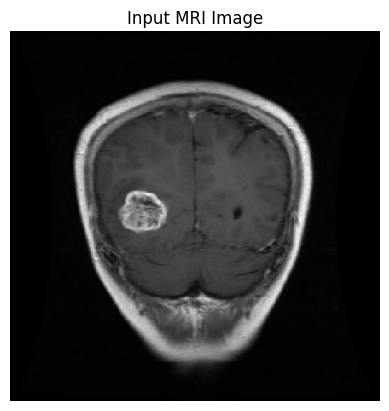

In [ ]:
img_path = "/content/Testing/glioma/Te-gl_157.jpg"  # change if needed

img = image.load_img(img_path, target_size=(224,224))
img_array = image.img_to_array(img)

img_array = np.expand_dims(img_array, axis=0)

plt.imshow(img)
plt.title("Input MRI Image")
plt.axis("off")
plt.show()

In [ ]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):

    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)

    return heatmap.numpy()

In [ ]:
def display_gradcam(img_path, heatmap, alpha=0.4):

    img = cv2.imread(img_path)
    img = cv2.resize(img, (224,224))

    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap = np.uint8(255 * heatmap)

    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    superimposed_img = cv2.addWeighted(img, 1-alpha, heatmap, alpha, 0)

    plt.imshow(superimposed_img)
    plt.axis("off")
    plt.show()

In [ ]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    22,151,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,737,102 (254.58 MB)

 Trainable params: 22,245,700 (84.86 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 44,491,402 (169.72 MB)

In [ ]:
# automatically find last conv layer
for layer in reversed(cnn_model.layers):
    if 'conv' in layer.name:
        last_conv_layer_name = layer.name
        break

print("Using layer:", last_conv_layer_name)

Using layer: conv2d_2


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model, Model

# Reload the cnn_model as its state might have been affected by previous operations
cnn_model_loaded = load_model('/content/drive/MyDrive/custom_cnn.keras')

# Convert the loaded Sequential model (cnn_model_loaded) to a Functional API model
# This ensures the model's inputs and outputs are properly defined for creating grad_model.
input_tensor = tf.keras.Input(shape=(224, 224, 3))
x = input_tensor
for layer in cnn_model_loaded.layers:
    x = layer(x)
cnn_functional_model = tf.keras.models.Model(inputs=input_tensor, outputs=x)

# IMPORTANT: Call cnn_functional_model once to ensure its graph is built
# Use a dummy input (e.g., zeros) of the expected shape
_ = cnn_functional_model(tf.zeros((1, 224, 224, 3)))

# Now create the grad_model using the cnn_functional_model
grad_model = tf.keras.models.Model(
    inputs=cnn_functional_model.inputs,
    outputs=[
        cnn_functional_model.get_layer(last_conv_layer_name).output,
        cnn_functional_model.output
    ]
)

In [ ]:
from tensorflow.keras.models import load_model
import tensorflow as tf
import numpy as np

cnn_model_loaded = load_model('/content/drive/MyDrive/custom_cnn.keras')

In [ ]:
for layer in reversed(cnn_model_loaded.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer_name = layer.name
        break

print("Last Conv Layer:", last_conv_layer_name)

Last Conv Layer: conv2d_2


In [ ]:
input_tensor = tf.keras.Input(shape=(224,224,3))
x = input_tensor

for layer in cnn_model_loaded.layers:
    x = layer(x)

cnn_functional_model = tf.keras.Model(inputs=input_tensor, outputs=x)

In [ ]:
_ = cnn_functional_model(tf.zeros((1,224,224,3)))

In [ ]:
grad_model = tf.keras.Model(
    inputs=cnn_functional_model.inputs,
    outputs=[
        cnn_functional_model.get_layer(last_conv_layer_name).output,
        cnn_functional_model.output
    ]
)

In [ ]:
print(img_array.shape)

(1, 224, 224, 3)


In [ ]:
cnn_model_loaded.predict(img_array)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 577ms/step


array([[0., 0., 1., 0.]], dtype=float32)

In [ ]:
import tensorflow as tf
tf.keras.backend.clear_session()

In [ ]:
from tensorflow.keras.models import load_model

cnn_model = load_model('/content/drive/MyDrive/custom_cnn.keras')

In [ ]:
dummy=tf.zeros((1,224,224,3))
_ = cnn_model(dummy)

In [ ]:
for layer in reversed(cnn_model.layers):
    if "conv" in layer.name:
        last_conv_layer_name = layer.name
        break

print("Last Conv Layer:", last_conv_layer_name)

Last Conv Layer: conv2d_2


In [ ]:
for i, layer in enumerate(cnn_functional_model.layers):
    if layer.name == last_conv_layer_name:
        last_conv_layer_index = i
        break

print("Conv layer index:", last_conv_layer_index)

Conv layer index: 5


In [ ]:
input_tensor = tf.keras.Input(shape=(224, 224, 3), name='gradcam_input')
x = input_tensor
conv_output_for_grad = None
for i, layer in enumerate(cnn_model.layers): # Iterate through the original cnn_model layers
    x = layer(x)
    if i == last_conv_layer_index: # Capture the output of the last conv layer
        conv_output_for_grad = x

model_output_for_grad = x # This is the output of the entire model

grad_model = tf.keras.models.Model(
    inputs=input_tensor,
    outputs=[
        conv_output_for_grad,
        model_output_for_grad
    ]
)

In [ ]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing import image # Import image utility

# Re-load the image and preprocess it to ensure valid input
img_path = "/content/Testing/glioma/Te-gl_157.jpg" # Use the same path as in sycMMLJ8ybqP
img = image.load_img(img_path, target_size=(224,224))
img_array = image.img_to_array(img)
img_array = img_array / 255.0  # Scale to 0-1 as per CNN model training
img_array = np.expand_dims(img_array, axis=0) # Add batch dimension

# Explicitly convert to tf.Tensor for robustness
img_array_tensor = tf.convert_to_tensor(img_array, dtype=tf.float32)

with tf.GradientTape() as tape:
    conv_outputs, predictions = grad_model(img_array_tensor)

    class_idx = tf.argmax(predictions[0])
    loss = predictions[:, class_idx]

grads = tape.gradient(loss, conv_outputs)

pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))

conv_outputs = conv_outputs[0]

heatmap_cnn = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)

heatmap_cnn = tf.maximum(heatmap_cnn, 0)
heatmap_cnn = heatmap_cnn / (tf.reduce_max(heatmap_cnn) + 1e-8)

heatmap_cnn = heatmap_cnn.numpy()

print("✅ CNN Grad-CAM generated successfully")

✅ CNN Grad-CAM generated successfully


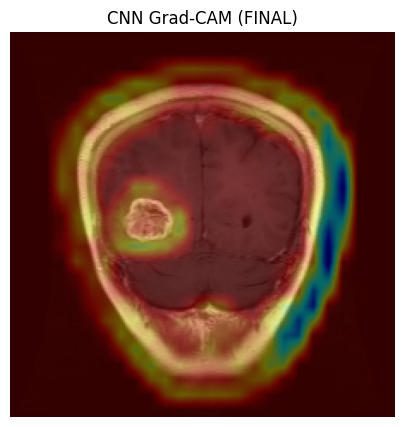

In [ ]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread(img_path)
img = cv2.resize(img, (224,224))

heatmap = cv2.resize(heatmap_cnn, (224,224))
heatmap = np.uint8(255 * heatmap)
heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

overlay = cv2.addWeighted(img, 0.6, heatmap, 0.4, 0)

plt.figure(figsize=(5,5))
plt.imshow(overlay)
plt.title("CNN Grad-CAM (FINAL)")
plt.axis("off")
plt.show()

In [ ]:
from tensorflow.keras.models import load_model
import tensorflow as tf
import numpy as np

resnet_model = load_model('/content/drive/MyDrive/Brain_Tumor_Research/ResNet50/resnet50_model.keras')

In [ ]:
from tensorflow.keras.applications.resnet50 import preprocess_input

img_resnet = preprocess_input(img_array.copy())

In [ ]:
_ = resnet_model(img_resnet)

In [ ]:
for layer in reversed(resnet_model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer_name_resnet = layer.name
        break

print("Last Conv Layer for ResNet50:", last_conv_layer_name_resnet)

Last Conv Layer for ResNet50: conv5_block3_3_conv


In [ ]:
# The resnet_model is already a functional model, so we can directly access its properties.
# We need to ensure the model's graph is built, which was done by the previous `_ = resnet_model(tf.zeros(...))` call.

# Create the Grad-CAM model by directly using the inputs and outputs of the pre-built resnet_model
grad_model_resnet = tf.keras.models.Model(
    inputs=resnet_model.inputs,
    outputs=[
        resnet_model.get_layer(last_conv_layer_name_resnet).output,
        resnet_model.output
    ]
)

In [ ]:
from tensorflow.keras.applications.resnet50 import preprocess_input

# Re-load the image and preprocess it specifically for ResNet50
img_path_resnet = "/content/Testing/glioma/Te-gl_157.jpg" # Use the same path as before
img_resnet_load = image.load_img(img_path_resnet, target_size=(224,224))
img_array_resnet = image.img_to_array(img_resnet_load)
img_array_resnet = np.expand_dims(img_array_resnet, axis=0)
img_array_resnet = preprocess_input(img_array_resnet)

# Generate the Grad-CAM heatmap using the ResNet50-specific model
heatmap_resnet = make_gradcam_heatmap(
    img_array_resnet,
    resnet_model,
    last_conv_layer_name_resnet
)

print("✅ ResNet50 Grad-CAM heatmap generated successfully")





✅ ResNet50 Grad-CAM heatmap generated successfully


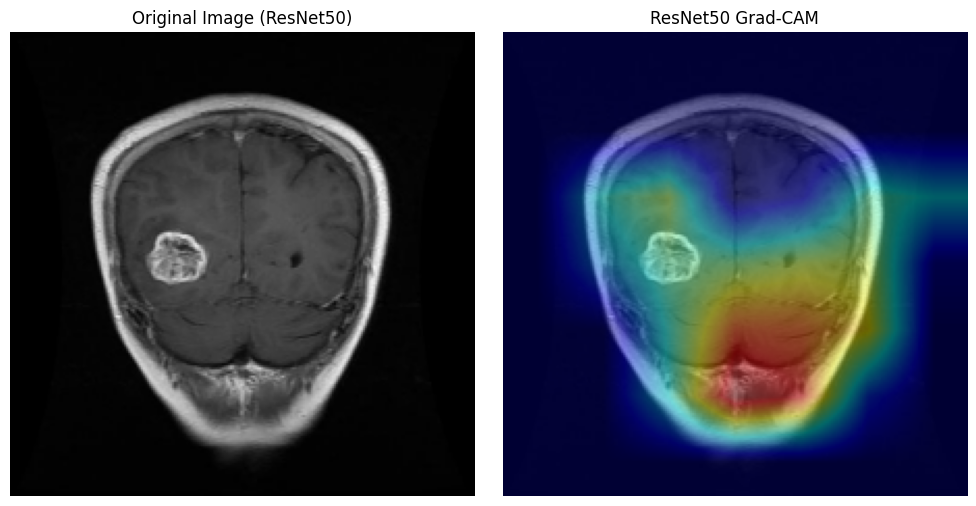

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load the original image
img_display = cv2.imread(img_path_resnet)
img_display = cv2.resize(img_display, (224, 224))
img_display = cv2.cvtColor(img_display, cv2.COLOR_BGR2RGB) # Convert BGR to RGB for matplotlib

# Resize the heatmap to the original image size
heatmap_resized = cv2.resize(heatmap_resnet, (img_display.shape[1], img_display.shape[0]))
heatmap_normalized = np.uint8(255 * heatmap_resized)

# Apply a colormap to the heatmap
heatmap_colored = cv2.applyColorMap(heatmap_normalized, cv2.COLORMAP_JET)
heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB) # Convert BGR to RGB

# Superimpose the heatmap on the original image
alpha = 0.4 # Transparency factor
superimposed_img_resnet = cv2.addWeighted(img_display, 1 - alpha, heatmap_colored, alpha, 0)

# Display the images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_display)
plt.title("Original Image (ResNet50)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(superimposed_img_resnet)
plt.title("ResNet50 Grad-CAM")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
for layer in reversed(mobilenet_model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer_name_mobilenet = layer.name
        break

print("Last Conv Layer for MobileNetV2:", last_conv_layer_name_mobilenet)

Last Conv Layer for MobileNetV2: Conv_1


In [ ]:
# The mobilenet_model is already a functional model.
# We need to ensure the model's graph is built, which was done implicitly during training.

# Create the Grad-CAM model by directly using the inputs and outputs of the pre-built mobilenet_model
grad_model_mobilenet = tf.keras.models.Model(
    inputs=mobilenet_model.inputs,
    outputs=[
        mobilenet_model.get_layer(last_conv_layer_name_mobilenet).output,
        mobilenet_model.output
    ]
)

In [ ]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Re-load the image and preprocess it specifically for MobileNetV2
img_path_mobilenet = "/content/Testing/glioma/Te-gl_157.jpg" # Using the same image as previous Grad-CAM examples
img_mobilenet_load = image.load_img(img_path_mobilenet, target_size=(224,224))
img_array_mobilenet = image.img_to_array(img_mobilenet_load)
img_array_mobilenet = np.expand_dims(img_array_mobilenet, axis=0)
img_array_mobilenet = preprocess_input(img_array_mobilenet)

# Generate the Grad-CAM heatmap using the MobileNetV2-specific model
heatmap_mobilenet = make_gradcam_heatmap(
    img_array_mobilenet,
    mobilenet_model,
    last_conv_layer_name_mobilenet
)

print("✅ MobileNetV2 Grad-CAM heatmap generated successfully")

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


✅ MobileNetV2 Grad-CAM heatmap generated successfully


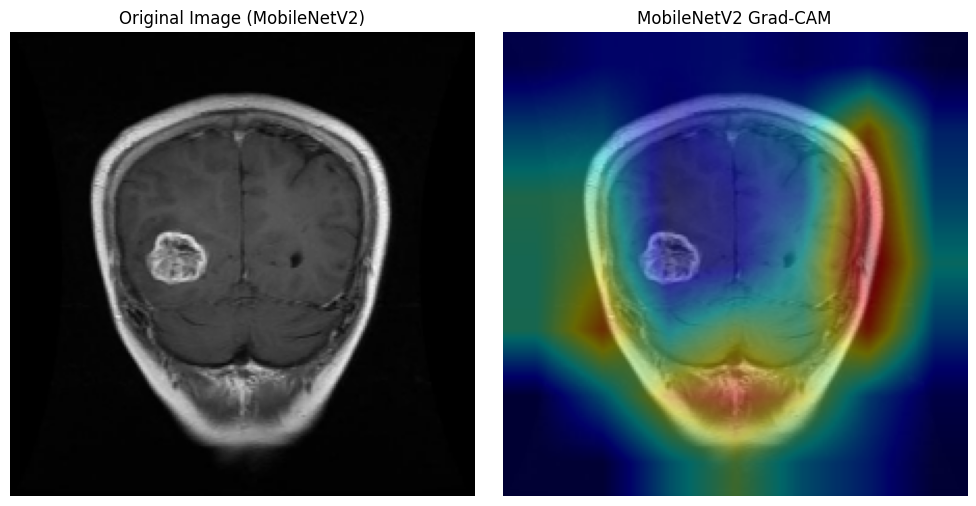

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load the original image for display
img_display_mobilenet = cv2.imread(img_path_mobilenet)
img_display_mobilenet = cv2.resize(img_display_mobilenet, (224, 224))
img_display_mobilenet = cv2.cvtColor(img_display_mobilenet, cv2.COLOR_BGR2RGB) # Convert BGR to RGB for matplotlib

# Resize the heatmap to the original image size
heatmap_resized_mobilenet = cv2.resize(heatmap_mobilenet, (img_display_mobilenet.shape[1], img_display_mobilenet.shape[0]))
heatmap_normalized_mobilenet = np.uint8(255 * heatmap_resized_mobilenet)

# Apply a colormap to the heatmap
heatmap_colored_mobilenet = cv2.applyColorMap(heatmap_normalized_mobilenet, cv2.COLORMAP_JET)
heatmap_colored_mobilenet = cv2.cvtColor(heatmap_colored_mobilenet, cv2.COLOR_BGR2RGB) # Convert BGR to RGB

# Superimpose the heatmap on the original image
alpha = 0.4 # Transparency factor
superimposed_img_mobilenet = cv2.addWeighted(img_display_mobilenet, 1 - alpha, heatmap_colored_mobilenet, alpha, 0)

# Display the images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_display_mobilenet)
plt.title("Original Image (MobileNetV2)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(superimposed_img_mobilenet)
plt.title("MobileNetV2 Grad-CAM")
plt.axis("off")

plt.tight_layout()
plt.show()

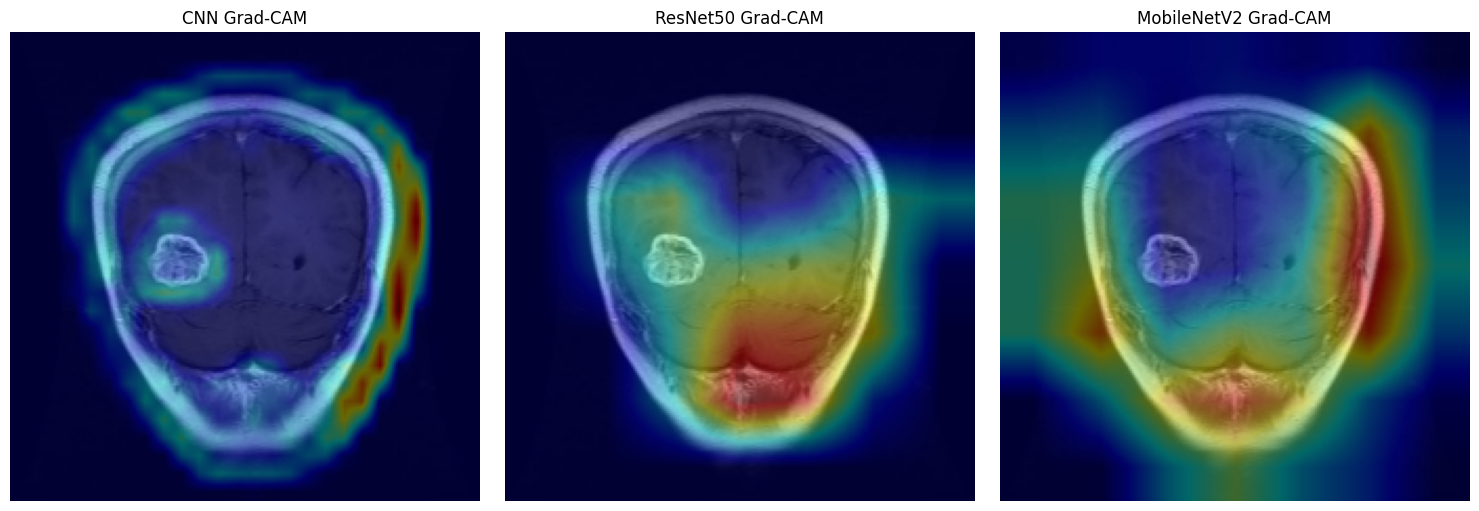

✅ Saved to Drive: /content/drive/MyDrive/Brain_Tumor_Research/GradCAM/FINAL_COMPARISON.png


In [ ]:
save_path = "/content/drive/MyDrive/Brain_Tumor_Research/GradCAM/FINAL_COMPARISON.png"

fig = plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
overlay(img_path, heatmap_cnn, "CNN Grad-CAM")

plt.subplot(1,3,2)
overlay(img_path, heatmap_resnet, "ResNet50 Grad-CAM")

plt.subplot(1,3,3)
overlay(img_path, heatmap_mobilenet, "MobileNetV2 Grad-CAM")

plt.tight_layout()

plt.savefig(save_path, dpi=300, bbox_inches='tight')

plt.show()

print("✅ Saved to Drive:", save_pa th)


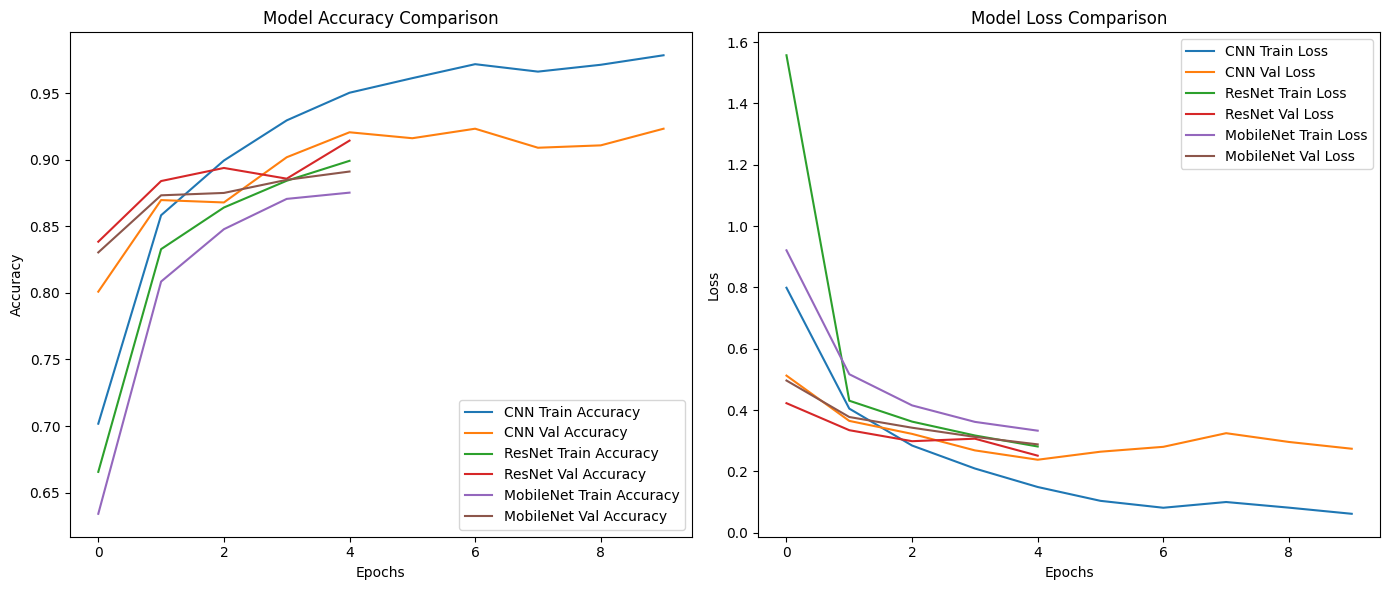

In [ ]:
import matplotlib.pyplot as plt

# Epoch range
epochs_cnn = range(len(history_cnn.history['accuracy']))
epochs_resnet = range(len(history_resnet.history['accuracy']))
epochs_mobilenet = range(len(history_mobilenet.history['accuracy']))

plt.figure(figsize=(14,6))

# ================= ACCURACY =================
plt.subplot(1,2,1)

plt.plot(epochs_cnn, history_cnn.history['accuracy'], label='CNN Train Accuracy')
plt.plot(epochs_cnn, history_cnn.history['val_accuracy'], label='CNN Val Accuracy')

plt.plot(epochs_resnet, history_resnet.history['accuracy'], label='ResNet Train Accuracy')
plt.plot(epochs_resnet, history_resnet.history['val_accuracy'], label='ResNet Val Accuracy')

plt.plot(epochs_mobilenet, history_mobilenet.history['accuracy'], label='MobileNet Train Accuracy')
plt.plot(epochs_mobilenet, history_mobilenet.history['val_accuracy'], label='MobileNet Val Accuracy')

plt.title('Model Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# ================= LOSS =================
plt.subplot(1,2,2)

plt.plot(epochs_cnn, history_cnn.history['loss'], label='CNN Train Loss')
plt.plot(epochs_cnn, history_cnn.history['val_loss'], label='CNN Val Loss')

plt.plot(epochs_resnet, history_resnet.history['loss'], label='ResNet Train Loss')
plt.plot(epochs_resnet, history_resnet.history['val_loss'], label='ResNet Val Loss')

plt.plot(epochs_mobilenet, history_mobilenet.history['loss'], label='MobileNet Train Loss')
plt.plot(epochs_mobilenet, history_mobilenet.history['val_loss'], label='MobileNet Val Loss')

plt.title('Model Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Get true labels
y_true = test_generator.classes
class_names = list(test_generator.class_indices.keys())

In [ ]:
y_pred_cnn = np.argmax(cnn_model.predict(test_generator), axis=1)
y_pred_resnet = np.argmax(resnet_model.predict(test_generator), axis=1)
y_pred_mobile = np.argmax(mobilenet_model.predict(test_generator), axis=1)

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 104ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 139ms/step


In [ ]:
cm_cnn = confusion_matrix(y_true, y_pred_cnn)
cm_resnet = confusion_matrix(y_true, y_pred_resnet)
cm_mobile = confusion_matrix(y_true, y_pred_mobile)

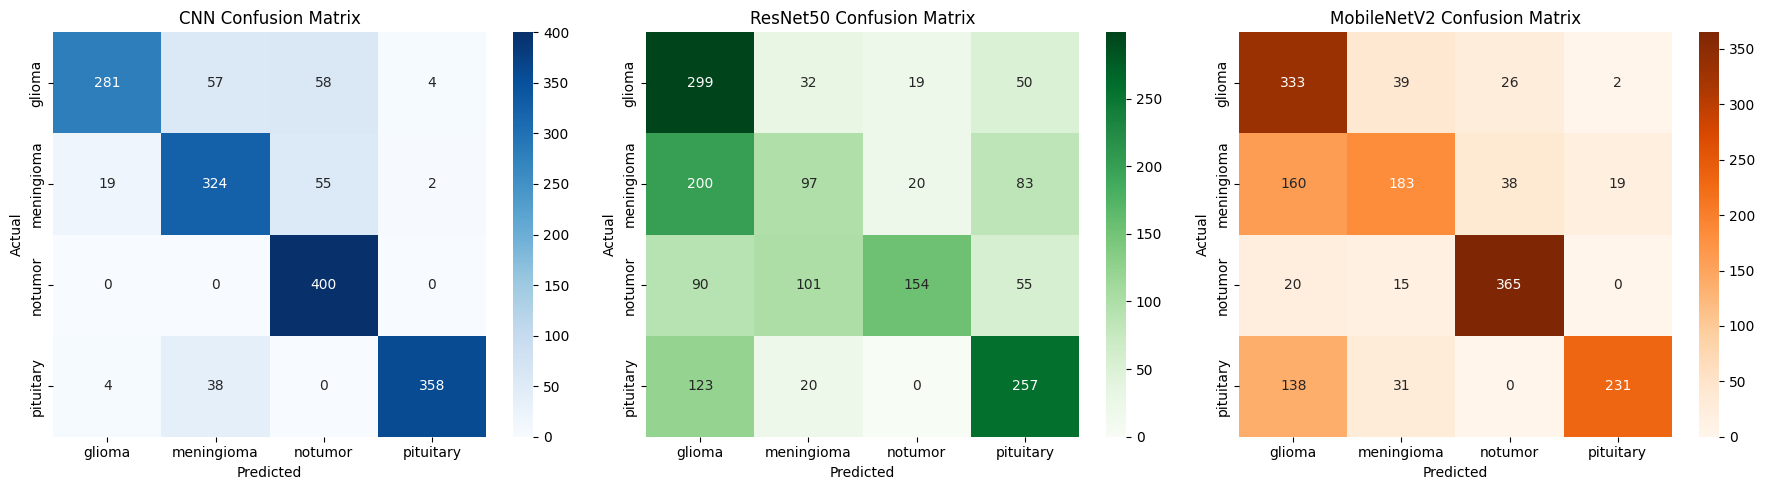

In [ ]:
plt.figure(figsize=(18,5))

# CNN
plt.subplot(1,3,1)
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

# ResNet
plt.subplot(1,3,2)
sns.heatmap(cm_resnet, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title("ResNet50 Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

# MobileNet
plt.subplot(1,3,3)
sns.heatmap(cm_mobile, annot=True, fmt='d', cmap='Oranges',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title("MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
plt.savefig("/content/drive/MyDrive/Brain_Tumor_Research/confusion_matrix_comparison.png",
            dpi=300,
            bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

In [ ]:
y_true = test_generator.classes
class_names = list(test_generator.class_indices.keys())

In [ ]:
y_pred_cnn = np.argmax(cnn_model.predict(test_generator), axis=1)
y_pred_resnet = np.argmax(resnet_model.predict(test_generator), axis=1)
y_pred_mobile = np.argmax(mobilenet_model.predict(test_generator), axis=1)

50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 103ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 85ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step


In [ ]:
print("===== CNN Classification Report =====")
report_cnn = classification_report(y_true, y_pred_cnn, target_names=class_names)
print(report_cnn)

print("\n===== ResNet50 Classification Report =====")
report_resnet = classification_report(y_true, y_pred_resnet, target_names=class_names)
print(report_resnet)

print("\n===== MobileNetV2 Classification Report =====")
report_mobile = classification_report(y_true, y_pred_mobile, target_names=class_names)
print(report_mobile)

===== CNN Classification Report =====
              precision    recall  f1-score   support

      glioma       0.92      0.70      0.80       400
  meningioma       0.77      0.81      0.79       400
     notumor       0.78      1.00      0.88       400
   pituitary       0.98      0.90      0.94       400

    accuracy                           0.85      1600
   macro avg       0.87      0.85      0.85      1600
weighted avg       0.87      0.85      0.85      1600


===== ResNet50 Classification Report =====
              precision    recall  f1-score   support

      glioma       0.42      0.75      0.54       400
  meningioma       0.39      0.24      0.30       400
     notumor       0.80      0.39      0.52       400
   pituitary       0.58      0.64      0.61       400

    accuracy                           0.50      1600
   macro avg       0.55      0.50      0.49      1600
weighted avg       0.55      0.50      0.49      1600


===== MobileNetV2 Classification Report =====
 

In [ ]:
with open("/content/drive/MyDrive/Brain_Tumor_Research/classification_report.txt", "w") as f:
    f.write("CNN Classification Report\n")
    f.write(report_cnn)
    f.write("\n\nResNet50 Classification Report\n")
    f.write(report_resnet)
    f.write("\n\nMobileNetV2 Classification Report\n")
    f.write(report_mobile)

print("✅ Saved classification report to Drive")

✅ Saved classification report to Drive


In [ ]:
import pandas as pd

def extract_metrics(report, model_name):
    lines = report.split('\n')[2:6]
    data = []
    for line in lines:
        parts = line.split()
        if len(parts) == 5:
            data.append(parts[:5])
    df = pd.DataFrame(data, columns=["Class", "Precision", "Recall", "F1-score", "Support"])
    df["Model"] = model_name
    return df

df_cnn = extract_metrics(report_cnn, "CNN")
df_resnet = extract_metrics(report_resnet, "ResNet50")
df_mobile = extract_metrics(report_mobile, "MobileNetV2")

final_df = pd.concat([df_cnn, df_resnet, df_mobile])
final_df

,Class,Precision,Recall,F1-score,Support,Model
0,glioma,0.92,0.70,0.80,400,CNN
1,meningioma,0.77,0.81,0.79,400,CNN
2,notumor,0.78,1.00,0.88,400,CNN
3,pituitary,0.98,0.90,0.94,400,CNN
0,glioma,0.42,0.75,0.54,400,ResNet50
1,meningioma,0.39,0.24,0.30,400,ResNet50
2,notumor,0.80,0.39,0.52,400,ResNet50
3,pituitary,0.58,0.64,0.61,400,ResNet50
0,glioma,0.51,0.83,0.63,400,MobileNetV2
1,meningioma,0.68,0.46,0.55,400,MobileNetV2


In [ ]:
save_df_path = "/content/drive/MyDrive/Brain_Tumor_Research/classification_metrics_comparison.csv"
final_df.to_csv(save_df_path, index=False)
print(f"✅ Saved classification metrics comparison to Drive: {save_df_path}")

✅ Saved classification metrics comparison to Drive: /content/drive/MyDrive/Brain_Tumor_Research/classification_metrics_comparison.csv


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'Aadhar', 'Classroom', 'SEM 7 Result .pdf', 'Modified MIS_REV_01.SLDDRW', 'Lighter than Air Systems certificate.pdf', 'NPTEL RECEIPT & RESULT.pdf', 'passbook pdf.pdf', 'Google AI Studio', 'Sarjerao patil (9890645256)\n26-5-2025\nVehicle No-....gsheet', 'Prototyping presentation.gslides', 'Minutes of Meetings Preparation.gvid', 'Advanced MoM Documentation & Governance.gslides', 'Practical Example of MOM Preparation.gslides', 'Minutes of Meetings Preparation.gslides', 'Brain_Tumor_Dataset', 'custom_cnn.keras', 'cnn_results.txt', 'cnn_accuracy.png', 'cnn_loss.png', 'cnn_confusion_matrix.png', 'Brain_Tumor_Results', 'Brain_Tumor_Research']
